# 04 · Perfiles de trabajadores y red neuronal (Producto 2)
**Parte A:** ¿qué tipos de trabajadores hay, sin usar la respuesta (informal / formal)?
**Parte B:** ¿una red neuronal mejora a nuestros mejores modelos?

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Datos: EPEN 2025 (INEI), departamento de Puno. El archivo está en data/ del repositorio.
NOMBRE = "21_Puno_EPEN_Anual_2025.csv"
RUTA = next((r for r in [f"../data/{NOMBRE}", f"data/{NOMBRE}", NOMBRE] if Path(r).exists()),
            "https://raw.githubusercontent.com/[USUARIO]/[REPOSITORIO]/main/data/" + NOMBRE)  # <- reemplazar

NUMERICAS = ["edad", "horas_semana", "ingreso_log", "n_limitaciones", "anios_estudio"]
CATEGORICAS = ["sexo", "area", "educacion", "lengua", "etnia", "ocupacion", "rama", "quiere_mas_horas"]

EDUC = {1: "Sin nivel/inicial", 2: "Sin nivel/inicial", 3: "Primaria incompleta", 4: "Primaria completa",
        5: "Secundaria incompleta", 6: "Secundaria completa", 7: "Sin nivel/inicial",
        8: "Superior no univ. incompleta", 9: "Superior no univ. completa",
        10: "Superior univ. incompleta", 11: "Superior univ. completa", 12: "Posgrado"}
ANIOS = {1: 0, 2: 0, 3: 3, 4: 6, 5: 8, 6: 11, 7: 0, 8: 12, 9: 14, 10: 13, 11: 16, 12: 18}  # años de estudio aprox.
OCUP = {0: "Fuerzas armadas", 1: "Directivos", 2: "Profesionales", 3: "Técnicos", 4: "Empleados de oficina",
        5: "Servicios y vendedores", 6: "Agricultores y pecuarios", 7: "Oficiales y artesanos",
        8: "Operadores de maquinaria", 9: "Ocupaciones elementales"}      # CIUO-08, gran grupo

def rama_ciiu(codigo):
    """Agrupa la división CIIU (4 dígitos, sin el cero inicial) en grandes ramas."""
    d = int(codigo) // 100
    if d <= 3:  return "Agricultura y pesca"
    if d <= 9:  return "Minería"
    if d <= 33: return "Manufactura"
    if d <= 39: return "Electricidad y agua"
    if d <= 43: return "Construcción"
    if d <= 47: return "Comercio"
    if d <= 53: return "Transporte"
    if d <= 56: return "Alojamiento y comidas"
    if d <= 82: return "Servicios a empresas"
    if d == 84: return "Administración pública"
    if d == 85: return "Educación"
    if d <= 88: return "Salud"
    return "Otros servicios y hogares"

def cargar_datos():
    raw = pd.read_csv(RUTA)
    # Población de estudio: personas OCUPADAS (OCUP300 = 1) con el indicador de informalidad del INEI
    d = raw[(raw["OCUP300"] == 1) & raw["Informal_P"].notna()].copy()
    out = pd.DataFrame({
        "edad": d["C208"], "horas_semana": d["whoraT"], "ingreso_log": np.log1p(d["INGTOTP"]),
        "n_limitaciones": (d[[f"C375_{i}" for i in range(1, 7)]] == 1).sum(axis=1),
        "anios_estudio": d["C366"].map(ANIOS),
        "sexo": d["C207"].map({1: "Hombre", 2: "Mujer"}),
        "area": d["AREA"].map({1: "Urbano", 2: "Rural"}),
        "educacion": d["C366"].map(EDUC),
        "lengua": d["C376"].map({1: "Quechua", 2: "Aimara", 10: "Castellano"}).fillna("Otra"),
        "etnia": d["C377"].map({1: "Quechua", 2: "Aimara", 6: "Blanco", 7: "Mestizo"}).fillna("Otra/No sabe"),
        "ocupacion": (d["C308_COD"] // 1000).map(OCUP),
        "rama": d["C309_COD"].map(rama_ciiu),
        "quiere_mas_horas": d["C333"].map({1: "Sí", 2: "No"}).fillna("No"),
        "informal": (d["Informal_P"] == 1).astype(int),     # 1 = empleo informal, 2 = formal (ver data/README.md)
        "grupo": d["LLAVE_PANEL"].astype(str),               # identifica a la persona (el panel la repite)
        "ingreso": d["INGTOTP"]})
    return out.reset_index(drop=True)

df = cargar_datos()
X, y, grupos = df[NUMERICAS + CATEGORICAS], df["informal"], df["grupo"]
print(df.shape, f"| empleo informal: {y.mean():.1%} | personas distintas: {grupos.nunique()}")

(7836, 16) | empleo informal: 77.8% | personas distintas: 5479


In [2]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Misma división en todos los notebooks: 80 % entrenamiento / 20 % test, sin repartir a una persona entre ambos
idx_tr, idx_te = next(StratifiedGroupKFold(5, shuffle=True, random_state=42).split(X, y, grupos))
X_tr, X_te, y_tr, y_te = X.iloc[idx_tr], X.iloc[idx_te], y.iloc[idx_tr], y.iloc[idx_te]
g_tr = grupos.iloc[idx_tr]
cv = StratifiedGroupKFold(5, shuffle=True, random_state=42)   # validación cruzada por persona

def preprocesador():
    num = Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())])
    cat = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num, NUMERICAS), ("cat", cat, CATEGORICAS)])

print(f"entrenamiento: {len(X_tr)} filas · test: {len(X_te)} filas · personas compartidas: {len(set(g_tr) & set(grupos.iloc[idx_te]))}")

entrenamiento: 6269 filas · test: 1567 filas · personas compartidas: 0


## Parte A · Perfiles con k-means (4 variables numéricas, escaladas)

k = 2: silueta = 0.309
k = 3: silueta = 0.303
k = 4: silueta = 0.268
k = 5: silueta = 0.262
k = 6: silueta = 0.269


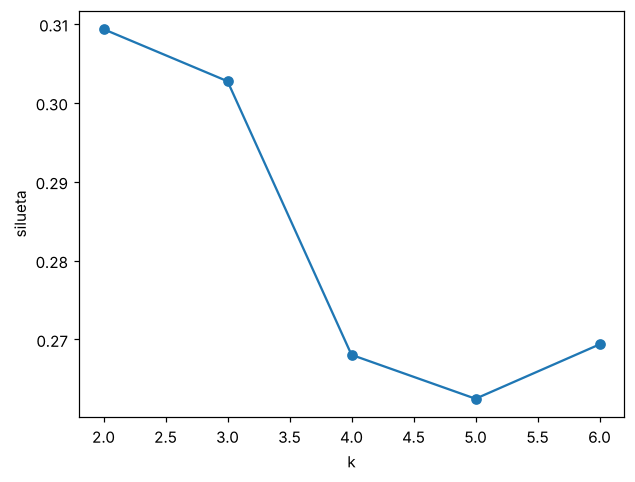

In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

VARS = ["edad", "horas_semana", "ingreso_log", "anios_estudio"]
Z = StandardScaler().fit_transform(df[VARS])
siluetas = {}
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    siluetas[k] = silhouette_score(Z, km.labels_, sample_size=3000, random_state=42)
    print(f"k = {k}: silueta = {siluetas[k]:.3f}")
plt.plot(list(siluetas), list(siluetas.values()), marker="o"); plt.xlabel("k"); plt.ylabel("silueta"); plt.show()

In [4]:
K = 3
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Z)
df["perfil"] = km.labels_
perfiles = df.groupby("perfil").agg(
    trabajadores=("informal", "size"), edad=("edad", "mean"), horas=("horas_semana", "mean"),
    ingreso_mediano=("ingreso", "median"), anios_estudio=("anios_estudio", "mean"),
    pct_rural=("area", lambda s: (s == "Rural").mean() * 100), pct_informal=("informal", lambda s: s.mean() * 100)).round(1)
perfiles.sort_values("pct_informal")

,trabajadores,edad,horas,ingreso_mediano,anios_estudio,pct_rural,pct_informal
perfil,,,,,,,
0,4253,42.0,47.6,1500.0,13.7,6.6,61.3
1,1649,30.0,20.0,134.0,11.3,16.9,97.3
2,1934,61.2,38.6,227.0,5.2,37.7,97.7


**Elección de k:** la silueta es casi igual con k = 2 (0,309) y k = 3 (0,303); elegimos **k = 3** porque separa a los informales en dos perfiles distintos y fáciles de describir.

**Lectura de los perfiles:**
- **Adultos con jornada completa (4 253 trabajadores):** 42 años, casi 48 horas semanales, ingreso mediano de S/ 1 500 y casi 14 años de estudio; casi todos son urbanos. **Informalidad de 61 %**: aquí están más del 90 % de los trabajadores formales.
- **Jóvenes con jornada parcial (1 649):** 30 años, 20 horas semanales y un ingreso mediano de solo S/ 134. **Informalidad de 97 %.**
- **Mayores con poca escolaridad (1 934):** 61 años, 5 años de estudio, ingreso mediano de S/ 227 y 38 % en el área rural. **Informalidad de 98 %.**

El algoritmo encontró **sin conocer la respuesta** dos perfiles donde casi nadie tiene un empleo formal. Juntos suman **3 583 trabajadores (46 %)**: es un criterio simple para focalizar programas de formalización y protección social.

## Parte B · Red neuronal (MLP) contra la logística y el boosting

In [5]:
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

red = Pipeline([("prep", preprocesador()),
                ("modelo", MLPClassifier(hidden_layer_sizes=(32, 16), early_stopping=True, max_iter=500, random_state=42))])
boosting = Pipeline([("prep", preprocesador()),
                     ("modelo", HistGradientBoostingClassifier(class_weight="balanced", random_state=42))])
logistica = Pipeline([("prep", preprocesador()),
                      ("modelo", LogisticRegression(max_iter=1000, class_weight="balanced"))])
resultados = {}
for nombre, m in [("Red neuronal (MLP)", red), ("Gradient boosting", boosting), ("Regresión logística", logistica)]:
    s = cross_val_score(m, X_tr, y_tr, cv=cv, groups=g_tr, scoring="roc_auc")
    resultados[nombre] = s
    print(f"{nombre:<22} ROC-AUC = {s.mean():.3f} ± {s.std():.3f}")

Red neuronal (MLP)     ROC-AUC = 0.947 ± 0.005
Gradient boosting      ROC-AUC = 0.948 ± 0.004
Regresión logística    ROC-AUC = 0.948 ± 0.004


**Conclusión:** la red neuronal **no supera** a los otros modelos (0,947 contra 0,948 de ROC-AUC, dentro del margen de error). En datos de tabla con pocas variables, una red rara vez compensa su complejidad y su menor interpretabilidad.